# Spatial autocorrelation

Companion notebook to [spatial_autocorrelation.md](../../notes/spatial_statistics/spatial_autocorrelation.md).
We compute global Moran's $I$ and Geary's $C$ by hand-sized examples, run permutation tests,
build local Moran statistics on a grid, and see how a trend mimics dependence.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
np.set_printoptions(precision=3, suppress=True)

def morans_i(x, W):
    z = x - x.mean()
    return len(x) / W.sum() * (z @ W @ z) / (z @ z)

def gearys_c(x, W):
    z = x - x.mean()
    d2 = (x[:, None] - x[None, :]) ** 2
    return (len(x) - 1) / (2 * W.sum()) * (W * d2).sum() / (z @ z)

def row_standardize(W):
    s = W.sum(1, keepdims=True)
    return np.divide(W, s, out=np.zeros_like(W, dtype=float), where=s > 0)

## 1. The five-location line from the note

Locations A-B-C-D-E, values $2,3,4,8,9$, row-standardized first-order neighbors.
The note reports $I\approx0.665$ and $C\approx0.206$.

In [2]:
x = np.array([2, 3, 4, 8, 9], float)
A = np.zeros((5, 5))
for i in range(4):
    A[i, i + 1] = A[i + 1, i] = 1
W = row_standardize(A)
z = x - x.mean()
print("z   =", z)
print("Wz  =", W @ z)
print("z'Wz=", z @ W @ z, " z'z=", z @ z)
print("Moran I =", round(morans_i(x, W), 4), "  E[I] =", -1 / (len(x) - 1))
print("Geary C =", round(gearys_c(x, W), 4))

z   = [-3.2 -2.2 -1.2  2.8  3.8]
Wz  = [-2.2 -2.2  0.3  1.3  2.8]
z'Wz= 25.800000000000004  z'z= 38.800000000000004
Moran I = 0.6649   E[I] = -0.25
Geary C = 0.2062


## 2. Exact permutation distribution

With $n=5$ there are only $5!=120$ arrangements, so we can enumerate the whole reference distribution
rather than sampling. The exact one-sided $p$-value is the share of arrangements with $I\ge I_{obs}$.

mean of permuted I: -0.25 (theory -0.25)
exact one-sided p = 0.05


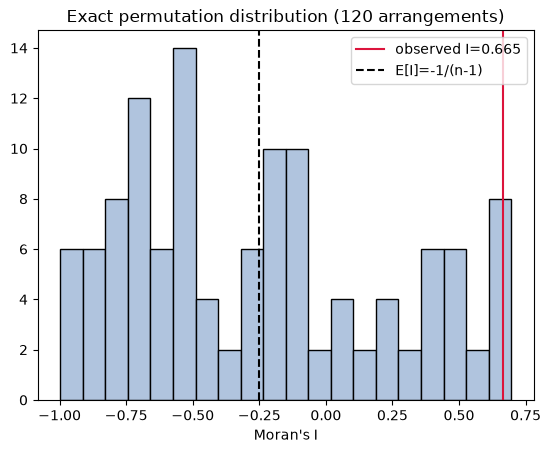

In [3]:
from itertools import permutations
I_obs = morans_i(x, W)
perm_I = np.array([morans_i(np.array(p), W) for p in permutations(x)])
p_exact = (perm_I >= I_obs - 1e-12).mean()
print("mean of permuted I:", perm_I.mean().round(4), "(theory -0.25)")
print("exact one-sided p =", p_exact)
plt.hist(perm_I, bins=20, color="lightsteelblue", edgecolor="k")
plt.axvline(I_obs, color="crimson", label=f"observed I={I_obs:.3f}")
plt.axvline(-0.25, color="k", ls="--", label="E[I]=-1/(n-1)")
plt.xlabel("Moran's I"); plt.legend(); plt.title("Exact permutation distribution (120 arrangements)")
plt.show()

The mean of the permutation distribution is exactly $-1/(n-1)=-0.25$, as the note states.
Only 6 of the 120 arrangements reach the observed value, giving $p=6/120=0.05$.

## 3. A 10 x 10 grid with spatially smooth values

We simulate a field by smoothing white noise with a moving average (queen neighbors), then test it with a
Monte Carlo permutation test and the pseudo-$p$ formula $(R+1)/(M+1)$.

In [4]:
m = 10
n = m * m
coords = np.array([(i, j) for i in range(m) for j in range(m)])
d = np.abs(coords[:, None, :] - coords[None, :, :]).max(axis=2)   # Chebyshev distance -> queen contiguity
Wq = row_standardize((d == 1).astype(float))

def smooth_field(noise, passes=2):
    f = noise.reshape(m, m)
    for _ in range(passes):
        g = np.pad(f, 1, mode="edge")
        f = sum(g[1 + a:1 + a + m, 1 + b:1 + b + m] for a in (-1, 0, 1) for b in (-1, 0, 1)) / 9
    return f.ravel()

field = smooth_field(rng.normal(size=n))
noise = rng.normal(size=n)

def mc_test(x, W, M=999, rng=rng):
    obs = morans_i(x, W)
    sims = np.array([morans_i(rng.permutation(x), W) for _ in range(M)])
    R = (sims >= obs).sum()
    return obs, (R + 1) / (M + 1), sims

for name, v in [("smooth field", field), ("white noise", noise)]:
    obs, p, _ = mc_test(v, Wq)
    print(f"{name:13s} I = {obs: .3f}  pseudo-p = {p:.3f}   (E[I] = {-1/(n-1):.4f})")

smooth field  I =  0.764  pseudo-p = 0.001   (E[I] = -0.0101)
white noise   I = -0.028  pseudo-p = 0.612   (E[I] = -0.0101)


## 4. Moran scatterplot and local Moran

The slope of $(Wz)_i$ on $z_i$ through the origin equals $I$ for a row-standardized $W$.
Local Moran $I_i=z_i(Wz)_i/m_2$ is assessed by conditional permutation (the value at $i$ is held fixed
and the remaining values are shuffled over its neighbors).

In [5]:
z = field - field.mean()
Wz = Wq @ z
print("slope through origin =", round((z @ Wz) / (z @ z), 4), " Moran I =", round(morans_i(field, Wq), 4))
m2 = (z @ z) / n
Ii = z * Wz / m2

others = [np.delete(np.arange(n), i) for i in range(n)]
nbrs = [np.flatnonzero(Wq[i]) for i in range(n)]
p_loc = np.empty(n)
for i in range(n):
    k = len(nbrs[i])
    sims = np.array([z[i] * rng.choice(z[others[i]], k, replace=False).mean() / m2 for _ in range(499)])
    p_loc[i] = ((sims >= Ii[i]).sum() + 1) / 500 if Ii[i] > 0 else ((sims <= Ii[i]).sum() + 1) / 500

# Benjamini-Hochberg
order = np.argsort(p_loc)
thr = 0.05 * (np.arange(1, n + 1) / n)
ok = p_loc[order] <= thr
k_max = np.flatnonzero(ok).max() + 1 if ok.any() else 0
sig_bh = np.zeros(n, bool); sig_bh[order[:k_max]] = True
print("unadjusted p<0.05:", (p_loc < 0.05).sum(), "| after BH(0.05):", sig_bh.sum())

slope through origin = 0.7636  Moran I = 0.7636


unadjusted p<0.05: 51 | after BH(0.05): 42


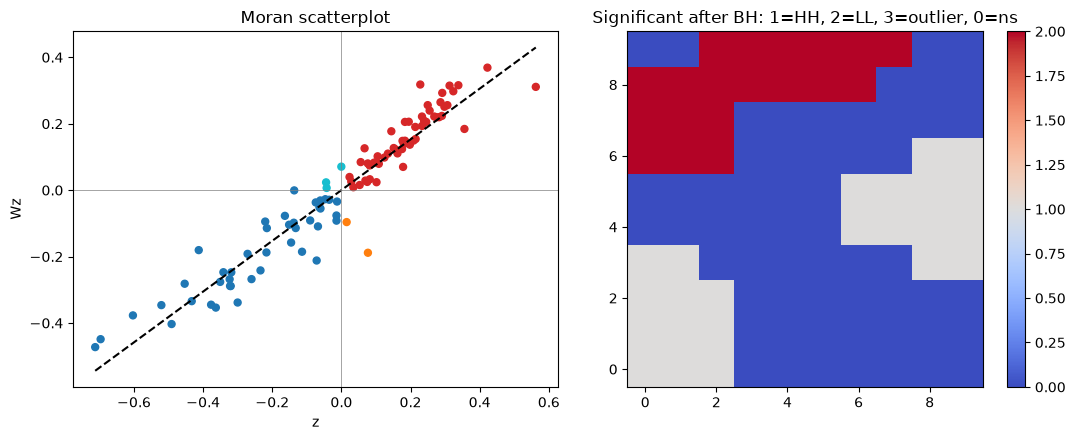

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
colors = np.where((z > 0) & (Wz > 0), "tab:red", np.where((z < 0) & (Wz < 0), "tab:blue",
          np.where((z > 0) & (Wz < 0), "tab:orange", "tab:cyan")))
ax[0].scatter(z, Wz, c=colors, s=25)
xs = np.array([z.min(), z.max()])
ax[0].plot(xs, xs * (z @ Wz) / (z @ z), "k--")
ax[0].axhline(0, color="gray", lw=.5); ax[0].axvline(0, color="gray", lw=.5)
ax[0].set_xlabel("z"); ax[0].set_ylabel("Wz"); ax[0].set_title("Moran scatterplot")
cat = np.where(sig_bh, np.where((z > 0) & (Wz > 0), 1, np.where((z < 0) & (Wz < 0), 2, 3)), 0)
im = ax[1].imshow(cat.reshape(m, m), cmap="coolwarm", origin="lower")
ax[1].set_title("Significant after BH: 1=HH, 2=LL, 3=outlier, 0=ns")
plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()

## 5. A trend mimics autocorrelation

Independent noise around a linear trend $5+0.5\,i$ along columns. Raw values show strong positive $I$;
residuals from the fitted trend do not. Note that the residual null mean is not exactly $-1/(n-1)$ (it depends on the design).

In [7]:
col = coords[:, 1].astype(float)
y = 5 + 0.5 * col + rng.normal(0, 1.0, n)
X = np.column_stack([np.ones(n), coords[:, 0], coords[:, 1]])
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
res = y - X @ beta
for name, v in [("raw values", y), ("residuals", res)]:
    obs, p, _ = mc_test(v, Wq, M=499)
    print(f"{name:11s} I = {obs: .3f}  pseudo-p = {p:.3f}")

raw values  I =  0.553  pseudo-p = 0.002
residuals   I = -0.034  pseudo-p = 0.626


## 6. Sensitivity to the weights

Distance-band weights at increasing radius: the statistic changes with the scale encoded in $W$.

band 1.0: I =  0.833
band 1.5: I =  0.764
band 2.0: I =  0.670
band 3.0: I =  0.473
band 5.0: I =  0.182
band 8.0: I = -0.008


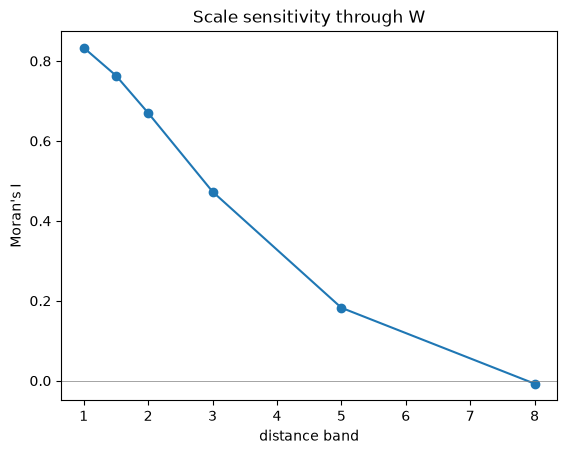

In [8]:
eu = np.sqrt(((coords[:, None, :] - coords[None, :, :]) ** 2).sum(2))
bands = [1.0, 1.5, 2.0, 3.0, 5.0, 8.0]
vals = []
for b in bands:
    Wb = row_standardize(((eu > 0) & (eu <= b)).astype(float))
    vals.append(morans_i(field, Wb))
    print(f"band {b:3.1f}: I = {vals[-1]: .3f}")
plt.plot(bands, vals, "o-"); plt.axhline(0, color="gray", lw=.5)
plt.xlabel("distance band"); plt.ylabel("Moran's I"); plt.title("Scale sensitivity through W"); plt.show()